In [1]:

%pip install -q numpy pandas scipy scikit-learn xgboost matplotlib shap joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import joblib
import shap

from pathlib import Path
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, log_loss
)

SEED = 42

LABELS = ["Low", "Mid", "High"]
LABEL_MAP = {"Low": 0, "Mid": 1, "High": 2}

BASIC = [
    "Age", "BodyTemp", "HeartRate",
    "SystolicBP", "DiastolicBP", "BMI"
]

FULL = BASIC + ["HbA1c", "FastingGlucose"]

# Locate the previously created files
cwd = Path.cwd()

if (cwd / "splits/train.csv").exists():
    BASE = cwd
elif (cwd / "output/splits/train.csv").exists():
    BASE = cwd / "output"
else:
    raise FileNotFoundError(
        f"Cannot locate splits. Working directory: {cwd}"
    )

DATA_DIR = BASE / "splits"
MODEL_DIR = BASE / "models"
RESULT_DIR = BASE / "section_4_2"

RESULT_DIR.mkdir(parents=True, exist_ok=True)

data = {
    name: pd.read_csv(DATA_DIR / f"{name}.csv")
    for name in [
        "train", "calibration", "policy_val", "test"
    ]
}

for name, df in data.items():
    assert df["row_id"].is_unique
    assert set(FULL + ["RiskLevel", "row_id"]).issubset(
        df.columns
    )
    assert df[FULL].notna().all().all()

    print(f"{name}: {len(df)} records")

print("\nRESULT DIRECTORY:", RESULT_DIR.resolve())
print("DATA LOADED SUCCESSFULLY!")


Note: you may need to restart the kernel to use updated packages.
train: 3634 records
calibration: 606 records
policy_val: 606 records
test: 1212 records

RESULT DIRECTORY: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_2
DATA LOADED SUCCESSFULLY!


In [2]:

basic_model = joblib.load(
    MODEL_DIR / "basic_model.joblib"
)

full_model = joblib.load(
    MODEL_DIR / "full_model.joblib"
)

with open(
    MODEL_DIR / "model_metadata.json",
    "r"
) as f:
    metadata = json.load(f)

print("Selected family:", metadata["selected_family"])
print("Basic model:", type(basic_model).__name__)
print("Full model:", type(full_model).__name__)

assert metadata["selected_family"] == "XGB"
assert np.array_equal(
    basic_model.classes_, [0, 1, 2]
)
assert np.array_equal(
    full_model.classes_, [0, 1, 2]
)

assert metadata["basic_features"] == BASIC
assert metadata["full_features"] == FULL

models = {
    "basic": basic_model,
    "full": full_model
}

features_by_model = {
    "basic": BASIC,
    "full": FULL
}

print("\nOFFICIAL XGBOOST MODELS LOADED!")


Selected family: XGB
Basic model: XGBClassifier
Full model: XGBClassifier

OFFICIAL XGBOOST MODELS LOADED!


In [3]:

def get_probs(model, frame, features):
    p = np.asarray(
        model.predict_proba(frame[features]),
        dtype=float
    )

    assert p.shape == (len(frame), 3)
    assert np.isfinite(p).all()
    assert np.allclose(
        p.sum(axis=1), 1.0, atol=1e-6
    )

    return p


for name in ["basic", "full"]:
    p = get_probs(
        models[name],
        data["calibration"],
        features_by_model[name]
    )

    print(f"\n{name.upper()} PROBABILITIES")
    display(
        pd.DataFrame(
            p[:5],
            columns=["p_Low", "p_Mid", "p_High"]
        ).round(5)
    )



BASIC PROBABILITIES


,p_Low,p_Mid,p_High
0,0.00003,0.00043,0.99954
1,0.00000,0.00037,0.99963
2,0.00000,0.00015,0.99985
3,0.00000,0.00303,0.99696
4,0.00003,0.00546,0.99452



FULL PROBABILITIES


,p_Low,p_Mid,p_High
0,0.00011,0.00051,0.99939
1,0.00002,0.00025,0.99972
2,0.00002,0.00014,0.99984
3,0.00004,0.00048,0.99948
4,0.00005,0.00084,0.99911


In [4]:

def temperature_scale(probs, T):
    logits = np.log(
        np.clip(probs, 1e-12, 1.0)
    ) / T

    logits -= np.max(
        logits, axis=1, keepdims=True
    )

    exp_logits = np.exp(logits)

    return exp_logits / exp_logits.sum(
        axis=1, keepdims=True
    )


def fit_temperature(probs, y_true):
    y = pd.Series(y_true).map(
        LABEL_MAP
    ).to_numpy()

    assert not np.isnan(y).any()

    def objective(T):
        calibrated = temperature_scale(
            probs, T
        )
        return log_loss(
            y, calibrated, labels=[0, 1, 2]
        )

    result = minimize_scalar(
        objective,
        bounds=(0.3, 5.0),
        method="bounded"
    )

    if not result.success:
        raise RuntimeError(
            "Temperature optimization failed."
        )

    return float(result.x)


temperatures = {}

for name in ["basic", "full"]:
    raw_p = get_probs(
        models[name],
        data["calibration"],
        features_by_model[name]
    )

    T = fit_temperature(
        raw_p,
        data["calibration"]["RiskLevel"]
    )

    temperatures[name] = T

    print(f"{name.upper()} Temperature: {T:.4f}")

with open(
    RESULT_DIR / "temperatures.json",
    "w"
) as f:
    json.dump(temperatures, f, indent=2)

print("\nCALIBRATION PARAMETERS SAVED!")


BASIC Temperature: 0.7186
FULL Temperature: 1.0061

CALIBRATION PARAMETERS SAVED!


In [5]:

predictions = {}

for name in ["basic", "full"]:
    model = models[name]
    features = features_by_model[name]
    T = temperatures[name]

    for split_name in ["policy_val", "test"]:
        df_split = data[split_name]

        raw_p = get_probs(
            model, df_split, features
        )

        calibrated_p = temperature_scale(
            raw_p, T
        )

        predictions[(name, split_name)] = {
            "raw": raw_p,
            "calibrated": calibrated_p
        }

        output = pd.DataFrame({
            "row_id": df_split["row_id"].to_numpy(),
            "p_Low": calibrated_p[:, 0],
            "p_Mid": calibrated_p[:, 1],
            "p_High": calibrated_p[:, 2]
        })

        assert output["row_id"].is_unique
        assert np.allclose(
            output[["p_Low", "p_Mid", "p_High"]]
            .sum(axis=1), 1
        )

        filename = f"{name}_{split_name}_probs.csv"

        output.to_csv(
            RESULT_DIR / filename,
            index=False
        )

        print("SAVED:", filename)

print("\nALL OFFICIAL PROBABILITIES EXPORTED!")


SAVED: basic_policy_val_probs.csv
SAVED: basic_test_probs.csv
SAVED: full_policy_val_probs.csv
SAVED: full_test_probs.csv

ALL OFFICIAL PROBABILITIES EXPORTED!


In [6]:

def multiclass_brier(y_labels, probs):
    y = pd.Series(y_labels).map(
        LABEL_MAP
    ).to_numpy()

    one_hot = np.eye(3)[y]

    return np.mean(
        np.sum((probs - one_hot) ** 2, axis=1)
    )


def high_risk_ece(y_labels, probs, n_bins=10):
    actual = (
        np.asarray(y_labels) == "High"
    ).astype(int)

    predicted = probs[:, 2]
    edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):
        left, right = edges[i], edges[i + 1]

        if i == n_bins - 1:
            mask = (
                (predicted >= left) &
                (predicted <= right)
            )
        else:
            mask = (
                (predicted >= left) &
                (predicted < right)
            )

        if not mask.any():
            continue

        bin_weight = mask.mean()
        observed_rate = actual[mask].mean()
        mean_prediction = predicted[mask].mean()

        ece += bin_weight * abs(
            observed_rate - mean_prediction
        )

    return float(ece)


def calculate_metrics(y_labels, probs):
    y = pd.Series(y_labels).map(
        LABEL_MAP
    ).to_numpy()

    pred = probs.argmax(axis=1)

    return {
        "Accuracy": accuracy_score(y, pred),
        "Macro_F1": f1_score(
            y, pred, average="macro"
        ),
        "High_Recall": recall_score(
            y, pred,
            labels=[2],
            average="macro",
            zero_division=0
        ),
        "Brier": multiclass_brier(
            y_labels, probs
        ),
        "LogLoss": log_loss(
            y, probs, labels=[0, 1, 2]
        ),
        "HighRisk_ECE": high_risk_ece(
            y_labels, probs
        )
    }


results = []

for name in ["basic", "full"]:
    for stage in ["raw", "calibrated"]:
        p = predictions[(name, "test")][stage]

        metrics = calculate_metrics(
            data["test"]["RiskLevel"],
            p
        )

        results.append({
            "Model": name,
            "Stage": stage,
            **metrics
        })

calibration_df = pd.DataFrame(results)

display(calibration_df.round(5))

calibration_df.to_csv(
    RESULT_DIR / "calibration_metrics.csv",
    index=False
)

print("RELIABILITY METRICS SAVED!")


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,Model,Stage,Accuracy,Macro_F1,High_Recall,Brier,LogLoss,HighRisk_ECE
0,basic,raw,0.89521,0.89385,0.76923,0.13991,0.25140,0.03510
1,basic,calibrated,0.89521,0.89385,0.76923,0.14103,0.24722,0.03403
2,full,raw,0.99422,0.99423,0.99007,0.00968,0.02461,0.00730
3,full,calibrated,0.99422,0.99423,0.99007,0.00969,0.02472,0.00744


RELIABILITY METRICS SAVED!


,Bin,N_Records,Mean_Predicted,Observed_Rate
0,"(-0.000815, 0.000534]",243,0.000394,0.000000
1,"(0.000534, 0.00121]",242,0.000804,0.000000
2,"(0.00121, 0.0114]",242,0.004229,0.004132
3,"(0.0114, 0.996]",242,0.648211,0.657025
4,"(0.996, 1.0]",243,0.998996,1.000000


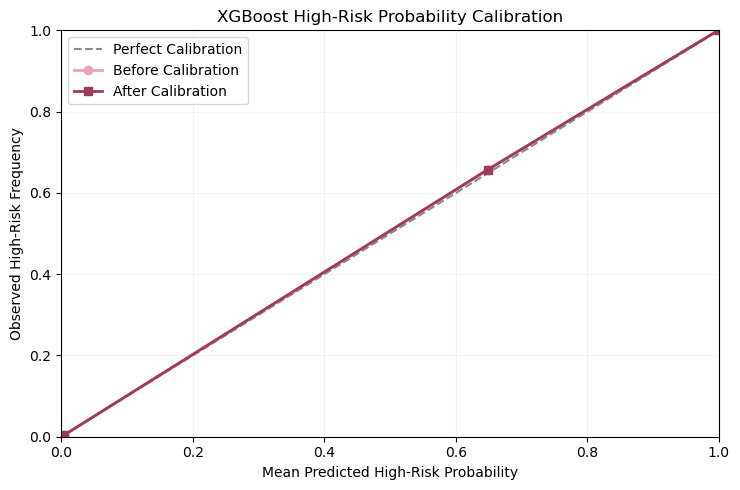

In [7]:

def calibration_bins(y_labels, p_high, q=5):
    actual = (
        np.asarray(y_labels) == "High"
    ).astype(int)

    df = pd.DataFrame({
        "Probability": p_high,
        "Actual": actual
    })

    df["Bin"] = pd.qcut(
        df["Probability"],
        q=q,
        duplicates="drop"
    )

    return (
        df.groupby("Bin", observed=True)
        .agg(
            N_Records=("Actual", "size"),
            Mean_Predicted=("Probability", "mean"),
            Observed_Rate=("Actual", "mean")
        )
        .reset_index()
    )


y_test_labels = data["test"]["RiskLevel"]

p_before = predictions[
    ("full", "test")
]["raw"][:, 2]

p_after = predictions[
    ("full", "test")
]["calibrated"][:, 2]

before = calibration_bins(
    y_test_labels, p_before
)

after = calibration_bins(
    y_test_labels, p_after
)

display(after)

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.plot(
    [0, 1], [0, 1],
    "--", color="#888888",
    label="Perfect Calibration"
)

ax.plot(
    before["Mean_Predicted"],
    before["Observed_Rate"],
    "o-",
    linewidth=2,
    color="#E9A3B7",
    label="Before Calibration"
)

ax.plot(
    after["Mean_Predicted"],
    after["Observed_Rate"],
    "s-",
    linewidth=2,
    color="#9F3A5B",
    label="After Calibration"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean Predicted High-Risk Probability")
ax.set_ylabel("Observed High-Risk Frequency")
ax.set_title("XGBoost High-Risk Probability Calibration")
ax.grid(alpha=0.15)
ax.legend()

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "calibration_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

after.to_csv(
    RESULT_DIR / "calibration_bin_counts.csv",
    index=False
)


Entropy by prediction correctness:


,count,mean,median
Correct,,,
False,7,0.36323,0.49552
True,1205,0.03864,0.01558


,Coverage_Percent,N_Selected,N_Errors,Error_Rate_Percent
0,10,122,0,0.0000
1,20,243,0,0.0000
2,30,364,0,0.0000
3,40,485,0,0.0000
4,50,606,0,0.0000
5,60,728,0,0.0000
6,70,849,0,0.0000
7,80,970,0,0.0000
8,90,1091,2,0.1833
9,100,1212,7,0.5776


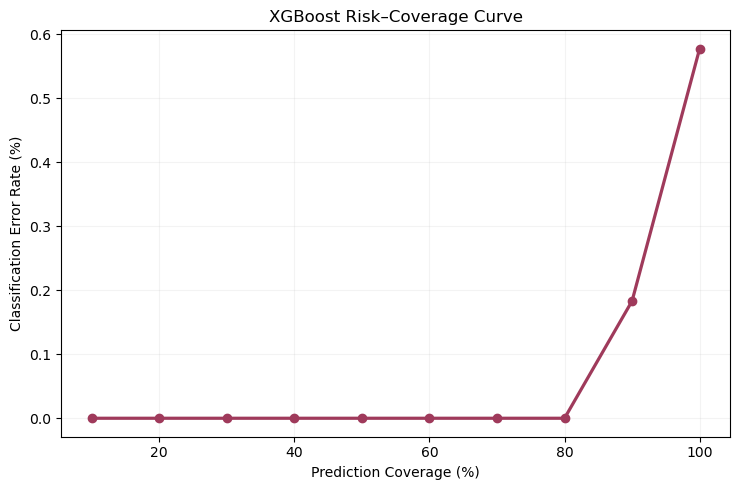

In [8]:

p = predictions[
    ("full", "test")
]["calibrated"]

y_true = data["test"]["RiskLevel"].map(
    LABEL_MAP
).to_numpy()

y_pred = p.argmax(axis=1)

# Normalized entropy
entropy = -np.sum(
    p * np.log(np.clip(p, 1e-12, 1.0)),
    axis=1
) / np.log(3)

correct = (y_true == y_pred)

uncertainty_df = pd.DataFrame({
    "row_id": data["test"]["row_id"].to_numpy(),
    "True_Label": np.array(LABELS)[y_true],
    "Predicted_Label": np.array(LABELS)[y_pred],
    "Entropy": entropy,
    "Correct": correct
})

print("Entropy by prediction correctness:")
display(
    uncertainty_df.groupby("Correct")["Entropy"]
    .agg(["count", "mean", "median"])
    .round(5)
)

uncertainty_df.to_csv(
    RESULT_DIR / "uncertainty_test.csv",
    index=False
)

# Lower entropy = selected first
order = np.argsort(entropy, kind="stable")

coverage_levels = range(10, 101, 10)
risk_rows = []

for coverage in coverage_levels:
    n_keep = int(np.ceil(
        len(y_true) * coverage / 100
    ))

    selected = order[:n_keep]

    error_rate = np.mean(
        y_pred[selected] != y_true[selected]
    )

    risk_rows.append({
        "Coverage_Percent": coverage,
        "N_Selected": n_keep,
        "N_Errors": int(
            (y_pred[selected] != y_true[selected]).sum()
        ),
        "Error_Rate_Percent": error_rate * 100
    })

risk_df = pd.DataFrame(risk_rows)

display(risk_df.round(4))

risk_df.to_csv(
    RESULT_DIR / "risk_coverage_results.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.plot(
    risk_df["Coverage_Percent"],
    risk_df["Error_Rate_Percent"],
    marker="o",
    linewidth=2.3,
    color="#9F3A5B"
)

ax.set_xlabel("Prediction Coverage (%)")
ax.set_ylabel("Classification Error Rate (%)")
ax.set_title("XGBoost Risk–Coverage Curve")
ax.grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "risk_coverage_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Feature,Mean_Absolute_SHAP
3,SystolicBP,0.11672
0,Age,0.07139
2,HeartRate,0.06518
6,HbA1c,0.04078
4,DiastolicBP,0.03537
7,FastingGlucose,0.03283
5,BMI,0.03224
1,BodyTemp,0.02354


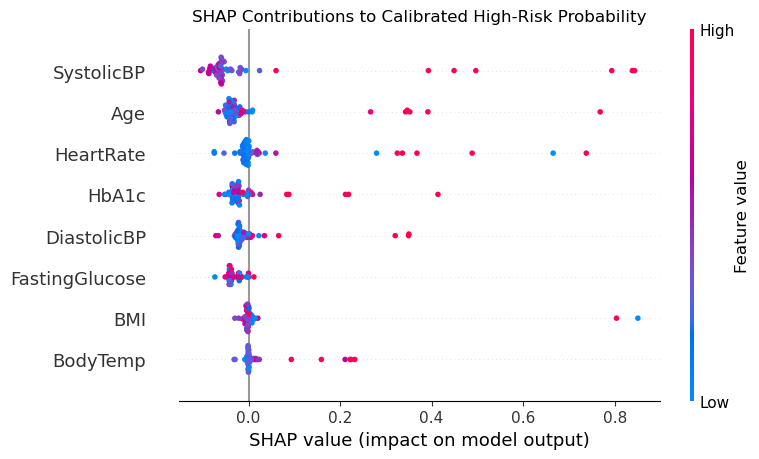

In [9]:

import shap

# Background from TRAINING only
background = data["train"][FULL].sample(
    n=25,
    random_state=SEED
).reset_index(drop=True)

# Records for explanation
sampled = data["test"].sample(
    n=60,
    random_state=SEED
).reset_index(drop=True)

X_explain = sampled[FULL].copy()


def predict_calibrated_high(x):
    X = pd.DataFrame(
        np.asarray(x),
        columns=FULL
    )

    raw_p = get_probs(
        full_model, X, FULL
    )

    calibrated_p = temperature_scale(
        raw_p,
        temperatures["full"]
    )

    return calibrated_p[:, 2]


explainer = shap.Explainer(
    predict_calibrated_high,
    masker=shap.maskers.Independent(background),
    algorithm="permutation"
)

shap_values = explainer(
    X_explain,
    max_evals=2 * len(FULL) + 1
)

assert shap_values.values.shape == (
    len(X_explain), len(FULL)
)

# Global importance
importance_df = pd.DataFrame({
    "Feature": FULL,
    "Mean_Absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(importance_df.round(5))

importance_df.to_csv(
    RESULT_DIR / "shap_feature_importance.csv",
    index=False
)

# Summary plot
shap.plots.beeswarm(
    shap_values,
    max_display=8,
    show=False
)

plt.title(
    "SHAP Contributions to Calibrated High-Risk Probability"
)
plt.tight_layout()

plt.gcf().savefig(
    RESULT_DIR / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Selected row_id: R003740
Actual class: High
Calibrated P(High): 0.99996


,Age,BodyTemp,HeartRate,SystolicBP,DiastolicBP,BMI,HbA1c,FastingGlucose
36,27,99.6,136,162,102,23.8,47,4.6


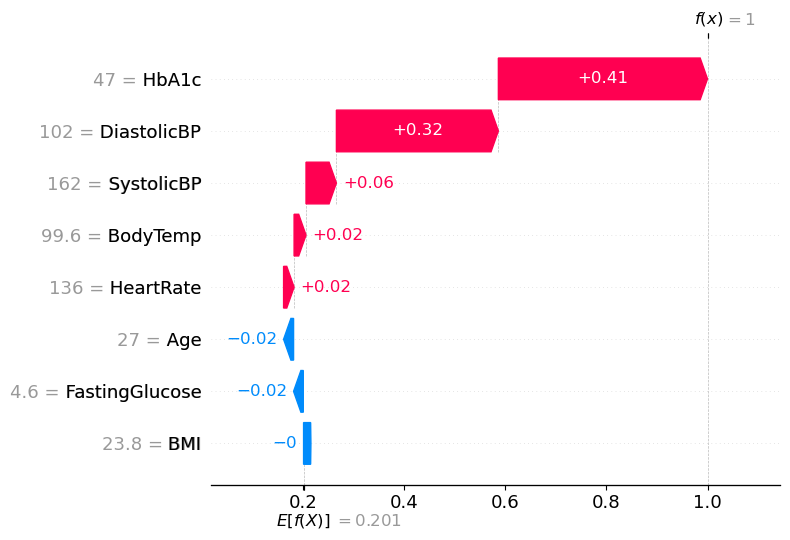

In [10]:

p_high_sample = predict_calibrated_high(
    X_explain
)

case_index = int(
    np.argmax(p_high_sample)
)

print("Selected row_id:",
      sampled.iloc[case_index]["row_id"])

print("Actual class:",
      sampled.iloc[case_index]["RiskLevel"])

print("Calibrated P(High):",
      round(p_high_sample[case_index], 5))

display(
    X_explain.iloc[[case_index]]
)

shap.plots.waterfall(
    shap_values[case_index],
    max_display=8,
    show=False
)

plt.tight_layout()

plt.gcf().savefig(
    RESULT_DIR / "shap_local_case.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

for name in ["basic", "full"]:
    for split_name in ["policy_val", "test"]:
        item = predictions[(name, split_name)]

        raw_p = item["raw"]
        cal_p = item["calibrated"]

        assert np.isfinite(cal_p).all()
        assert np.all((cal_p >= 0) & (cal_p <= 1))
        assert np.allclose(cal_p.sum(axis=1), 1)

        assert np.array_equal(
            raw_p.argmax(axis=1),
            cal_p.argmax(axis=1)
        ), "Unexpected class change after calibration"

        print(
            f"PASS: {name} / {split_name} "
            f"({len(cal_p)} records)"
        )

delivery_metadata = {
    "source_section": "4.1 + 4.2",
    "model_family": metadata["selected_family"],
    "model_type": "XGBoost",
    "class_order": LABELS,
    "basic_features": BASIC,
    "full_features": FULL,
    "calibration_method": "Temperature Scaling",
    "calibration_fit_split": "calibration",
    "probability_export_splits": [
        "policy_val", "test"
    ],
    "seed": SEED,
    "temperature_values": temperatures
}

with open(
    RESULT_DIR / "delivery_metadata.json",
    "w"
) as f:
    json.dump(
        delivery_metadata,
        f,
        indent=2
    )

print("\nSECTION 4.2 COMPLETED!")
print("All outputs:", RESULT_DIR.resolve())


PASS: basic / policy_val (606 records)
PASS: basic / test (1212 records)
PASS: full / policy_val (606 records)
PASS: full / test (1212 records)

SECTION 4.2 COMPLETED!
All outputs: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_2


In [12]:

# Compare raw vs calibrated probabilities on Policy Validation
# Do not use TEST metrics to choose calibration.

rows = []

for name in ["basic", "full"]:
    frame = data["policy_val"]
    raw_p = get_probs(
        models[name],
        frame,
        features_by_model[name]
    )
    calibrated_p = temperature_scale(
        raw_p, temperatures[name]
    )

    for stage, p in [
        ("Raw", raw_p),
        ("Calibrated", calibrated_p)
    ]:
        m = calculate_metrics(
            frame["RiskLevel"], p
        )

        rows.append({
            "Model": name,
            "Stage": stage,
            "Brier": m["Brier"],
            "LogLoss": m["LogLoss"],
            "HighRisk_ECE": m["HighRisk_ECE"]
        })

policy_calibration_df = pd.DataFrame(rows)

display(policy_calibration_df.round(5))

policy_calibration_df.to_csv(
    RESULT_DIR / "policy_validation_calibration_check.csv",
    index=False
)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,Model,Stage,Brier,LogLoss,HighRisk_ECE
0,basic,Raw,0.13768,0.25469,0.03125
1,basic,Calibrated,0.14032,0.25773,0.03484
2,full,Raw,0.02508,0.05870,0.01024
3,full,Calibrated,0.02506,0.05858,0.01021
